### Goals

- gather models trained on different folds with different setups
- aggregate over diffferent folds, and seeds if applicable
- with each model, predict the entire training dataset (through the different folds) 
- evaluate


In [117]:
import sys
import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import os 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')
import tqdm

import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [118]:
import sys
sys.path.append('../')
from evaluate import compute_and_log_metrics


### Examples of how to filter wandb runs:

example_filters = {


    "group" : "17/5 single-bi-trimodal",
    "config.image_encoder.use": True,
    "config.batch_size": {'$gt': 10}, #Greater than
    "config.batch_size": {'$lte': 10}, #Less than or equal
}

In [119]:
# Define the filter criteria
filter_criteria = {
    'config.image_encoder.use': True,
    'config.tabular_encoder.use': True,
    'config.loc_encoder.use': True,
    "group" : "17/5 single-bi-trimodal",
}


In [120]:
models = utils.get_wandb_runs(filter_criteria)

print(f'models: {len(models)}')

models: 24


In [121]:
'''
In some cases, the wandb API filtering doesn't work;
If I get 0 models returned, I need to 
    1. remove the problematic filter
    2. get all the runs
    3. filter manually as below
'''
#Example:
#selected_models = [model for model in models  if model['config']['train dst size'] > 10000]  
#print(len(selected_models))
#models = selected_models

"\nIn some cases, the wandb API filtering doesn't work;\nIf I get 0 models returned, I need to \n    1. remove the problematic filter\n    2. get all the runs\n    3. filter manually as below\n"

In [122]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
n_classes = 12


In [124]:
for model_dict in tqdm.tqdm(models):

    metrics, preds = utils.load_model_and_predict(model_dict, n_classes, device)
    model_dict['predictions'] = preds
    model_dict['metrics'] = metrics

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 24/24 [10:17<00:00, 25.74s/it]


In [44]:
import importlib
importlib.reload(utils)


<module 'utils' from '/home/jan/Documents/EPFL/project_2/notebooks/../utils.py'>

In [125]:
hyperparams_values = utils.find_keys_with_multiple_values([model['config'] for model in models])

In [126]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v4/labels_55k.csv")
labels = labels.loc[labels['split_5'] != 4 ].reset_index(drop=True) #This is test split, not used 

targets = labels['driver'].map(LABEL_MAPPING).to_numpy()

#Get indices of dataset examples for each data split
indices_for_each_split = {}
for split in labels['split_5'].unique():
    indices_for_each_split[split] = labels.loc[labels['split_5'] == split].index.tolist()

In [127]:
def get_models_with_config(_models, target_config):
    models_with_this_config_combination = []
    for model in _models:
        skip_model = False
        for key in target_config.keys():
            if model['config'][key] != target_config[key]:
                skip_model = True
                break
        if skip_model:
            continue
        models_with_this_config_combination.append(model)
    
    return models_with_this_config_combination

In [141]:
exclude_keys = ['folds_to_split', 'seed']

combinations = utils.generate_combinations(hyperparams_values, exclude_keys)

In [142]:
combinations

[{'train_examples_per_class': 1000}, {'train_examples_per_class': 50}]

In [143]:

performance_per_configuration = {}

for combo in combinations:
    
    metrics_per_random_seed = []
    
    combo_str = ' '.join(pformat(combo, width=1).split())
    
    #Compute metrics per each random seed separately
    for seed in hyperparams_values['seed']:
        combo['seed'] = seed
        
        #Get all models that have the configuration setup 
        #(only difference is the excluded key 'folds_to_split')
        models_with_this_config = get_models_with_config(models, combo)

        #Init an empty array of the entire train+val size
        predictions_over_all_folds = np.full(labels.shape[0], np.nan)

        #Populate the array with the combined predictions of the 4-fold models
        #Each model is trained on 3/4 folds and predicts on the 4th fold
        for model in models_with_this_config:
            
            validation_split = int(utils.find_key_for_value(model['config']['folds_to_split']['mapping'], 'val'))
            indices_of_examples = indices_for_each_split[validation_split]
            predictions_over_all_folds[indices_of_examples] = model['predictions']

        #Now, predictions_over_all_folds should contain predictions over the entire training dataset
        # for a given configuration
        assert np.isnan(predictions_over_all_folds).any() == False  


        #compute metrics for this configuration
        metrics = compute_and_log_metrics(targets, predictions_over_all_folds, dataset_name='', log_to_wandb=False, losses=None)  
        metrics_per_random_seed.append(pd.DataFrame(metrics))


    if not metrics_per_random_seed:
        print("no metrics for: ", combo)
        continue


    # Concatenate DataFrames along a new axis
    concat_df = pd.concat(metrics_per_random_seed, keys=range(len(metrics_per_random_seed)))

    # Compute the mean along the new axis
    mean_df = concat_df.groupby(level=1).mean()

    # Compute the standard deviation along the new axis
    std_df = concat_df.groupby(level=1).std()   
    
    

    performance_per_configuration[combo_str] = {}
    performance_per_configuration[combo_str]['mean'] = mean_df
    performance_per_configuration[combo_str]['std'] = std_df



        

In [144]:
list(performance_per_configuration.keys())

["{'train_examples_per_class': 1000}", "{'train_examples_per_class': 50}"]

In [146]:
performance_per_configuration["{'train_examples_per_class': 1000}"]['mean']

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,other,accuracy,macro avg,weighted avg
f1-score,0.815108,0.775728,0.863559,0.655781,0.782194,0.815233,0.921392,0.966702,0.821496,0.712050,0.978532,0.807384,0.844395,0.826263,0.843760
precision,0.793926,0.827147,0.845876,0.635325,0.752863,0.832657,0.929324,0.947677,0.828179,0.719661,0.965025,0.817867,0.844395,0.824627,0.845013
recall,0.838519,0.730674,0.883420,0.691617,0.813906,0.799038,0.913737,0.986567,0.814932,0.708345,0.992432,0.797209,0.844395,0.830866,0.844395
support,2089.000000,4161.000000,2885.000000,334.000000,4075.000000,4437.000000,4096.000000,4814.000000,4438.000000,3647.000000,3920.000000,3654.000000,0.844395,42550.000000,42550.000000


In [147]:
performance_per_configuration["{'train_examples_per_class': 50}"]['mean']

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,other,accuracy,macro avg,weighted avg
f1-score,0.661244,0.580879,0.772907,0.350855,0.646365,0.677146,0.845521,0.944577,0.717763,0.572400,0.958079,0.680445,0.734853,0.700682,0.735823
precision,0.619489,0.666304,0.760053,0.239982,0.631938,0.773971,0.872577,0.909014,0.757952,0.573038,0.946419,0.635604,0.734853,0.698862,0.747003
recall,0.715015,0.516462,0.791219,0.706587,0.667566,0.602509,0.820638,0.983036,0.685143,0.574810,0.970153,0.733260,0.734853,0.730533,0.734853
support,2089.000000,4161.000000,2885.000000,334.000000,4075.000000,4437.000000,4096.000000,4814.000000,4438.000000,3647.000000,3920.000000,3654.000000,0.734853,42550.000000,42550.000000


In [148]:
class_names = list(LABEL_MAPPING.keys())

In [149]:
class_names.append('accuracy')

In [151]:
stats = {}
for model_name, model_stats in performance_per_configuration.items():
    stats[model_name] = {}
    for cls in class_names:
        stats[model_name][cls] = {}
        stats[model_name][cls]['score'] = performance_per_configuration[model_name]['mean'][cls]['f1-score']
        stats[model_name][cls]['std'] = performance_per_configuration[model_name]['std'][cls]['f1-score']
        

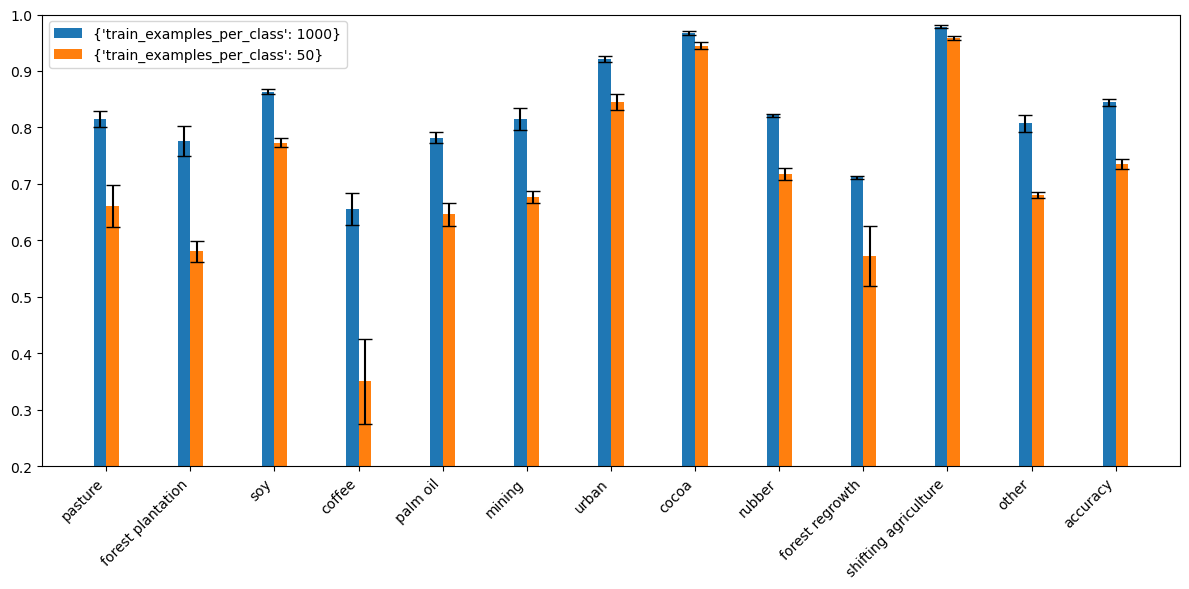

In [158]:
import matplotlib.pyplot as plt



# Initialize plot
fig, ax = plt.subplots(figsize=(12, 6))

# Set the width of the bars
bar_width = 0.15

# Set positions of the bars on the x-axis
index = np.arange(len(class_names))

# Plot each model's data

#for i, model in enumerate(stats.keys()):
for i, model in enumerate(list(performance_per_configuration.keys())): #only models with image
    scores = [stats[model][cls]['score'] for cls in class_names]
    stds = [stats[model][cls]['std'] for cls in class_names]
    ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

# Set labels, title, and legend
#ax.set_xlabel('Class')
#ax.set_ylabel('Score')
plt.ylim(bottom=0.2)
plt.ylim(top=1)
ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.legend()

# Show plot
plt.tight_layout()
plt.show()

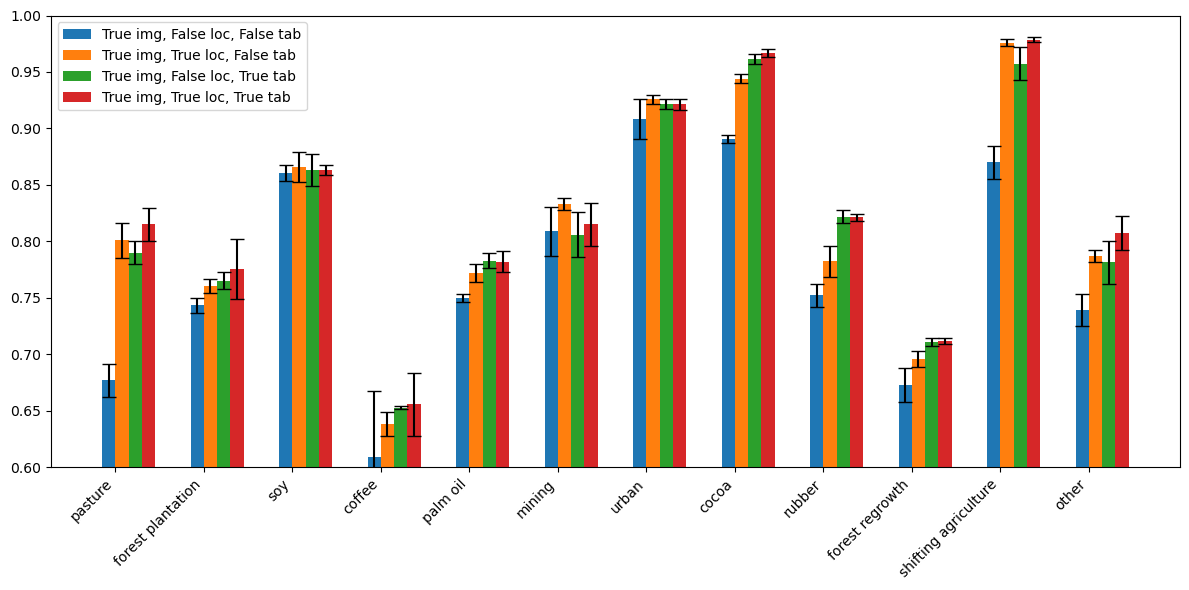

In [195]:
import matplotlib.pyplot as plt


# Extract classes and models
classes = list(stats['False img, False loc, True tab'].keys())
models = list(stats.keys())

# Initialize plot
fig, ax = plt.subplots(figsize=(12, 6))

# Set the width of the bars
bar_width = 0.15

# Set positions of the bars on the x-axis
index = np.arange(len(classes))

# Plot each model's data

#for i, model in enumerate(stats.keys()):
for i, model in enumerate(list(performance_per_configuration.keys())): #only models with image
    scores = [stats[model][cls]['score'] for cls in classes]
    stds = [stats[model][cls]['std'] for cls in classes]
    ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

# Set labels, title, and legend
#ax.set_xlabel('Class')
#ax.set_ylabel('Score')
plt.ylim(bottom=0.6)
plt.ylim(top=1)
ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(classes, rotation=45, ha='right')
ax.legend()

# Show plot
plt.tight_layout()
plt.show()

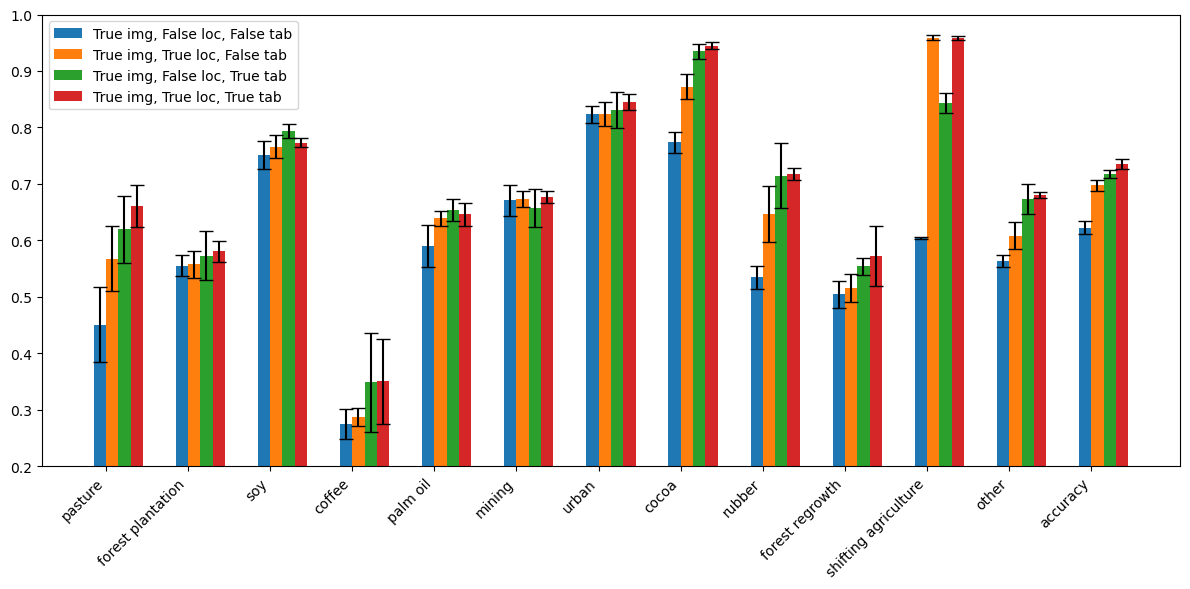

In [44]:
import matplotlib.pyplot as plt


# Extract classes and models
classes = list(stats['False img, False loc, True tab'].keys())
models = list(stats.keys())

# Initialize plot
fig, ax = plt.subplots(figsize=(12, 6))

# Set the width of the bars
bar_width = 0.15

# Set positions of the bars on the x-axis
index = np.arange(len(classes))

# Plot each model's data

#for i, model in enumerate(stats.keys()):
for i, model in enumerate(img_only_reordered): #only models with image
    scores = [stats[model][cls]['score'] for cls in classes]
    stds = [stats[model][cls]['std'] for cls in classes]
    ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

# Set labels, title, and legend
#ax.set_xlabel('Class')
#ax.set_ylabel('Score')
plt.ylim(bottom=0.2)
plt.ylim(top=1)
ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(classes, rotation=45, ha='right')
ax.legend()

# Show plot
plt.tight_layout()
plt.show()

In [45]:
x = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/tabular/deduce_yearly.csv")

In [46]:
x.loc[x.country == 'Colombia'].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,ColombiaColombiaColombiaColombiaColombiaColomb...,64.182842,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,ColombiaColombiaColombiaColombiaColombiaColomb...,1.939646,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",ColombiaColombiaColombiaColombiaColombiaColomb...,2.231461,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Bamboo),ColombiaColombiaColombiaColombiaColombiaColomb...,0.000110,Forest plantationForest plantationForest plant...,44253
Forest plantation (Unclassified),ColombiaColombiaColombiaColombiaColombiaColomb...,3.981368,Forest plantationForest plantationForest plant...,44253
Leather,ColombiaColombiaColombiaColombiaColombiaColomb...,3.378044,PasturePasturePasturePasturePasturePasturePast...,44253
Natural rubber in primary forms,ColombiaColombiaColombiaColombiaColombiaColomb...,0.687743,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
Oil palm fruit,ColombiaColombiaColombiaColombiaColombiaColomb...,5.336640,Oilseeds and oleaginous fruitsOilseeds and ole...,44253
Soya beans,ColombiaColombiaColombiaColombiaColombiaColomb...,0.442013,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [215]:
x.loc[x.country == 'Bolivia (Plurinational State of)'].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,Bolivia (Plurinational State of)Bolivia (Pluri...,47.307818,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,Bolivia (Plurinational State of)Bolivia (Pluri...,0.095735,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",Bolivia (Plurinational State of)Bolivia (Pluri...,0.165045,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Unclassified),Bolivia (Plurinational State of)Bolivia (Pluri...,0.000029,Forest plantationForest plantationForest plant...,44253
Leather,Bolivia (Plurinational State of)Bolivia (Pluri...,2.489885,PasturePasturePasturePasturePasturePasturePast...,44253
Soya beans,Bolivia (Plurinational State of)Bolivia (Pluri...,16.963033,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [216]:
x.loc[x.country == 'Viet Nam'].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,Viet NamViet NamViet NamViet NamViet NamViet N...,7.397770,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,Viet NamViet NamViet NamViet NamViet NamViet N...,0.206834,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",Viet NamViet NamViet NamViet NamViet NamViet N...,4.145469,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Australian Blackwood),Viet NamViet NamViet NamViet NamViet NamViet N...,0.000010,Forest plantationForest plantationForest plant...,44253
Forest plantation (Unclassified),Viet NamViet NamViet NamViet NamViet NamViet N...,16.717140,Forest plantationForest plantationForest plant...,44253
Leather,Viet NamViet NamViet NamViet NamViet NamViet N...,0.389356,PasturePasturePasturePasturePasturePasturePast...,44253
Natural rubber in primary forms,Viet NamViet NamViet NamViet NamViet NamViet N...,25.573644,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
Oil palm fruit,Viet NamViet NamViet NamViet NamViet NamViet N...,0.001041,Oilseeds and oleaginous fruitsOilseeds and ole...,44253
Soya beans,Viet NamViet NamViet NamViet NamViet NamViet N...,0.302824,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [224]:
x.loc[x.country == 'Brazil'].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,75.068,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,0.348,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,0.400,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Birch),BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,0.000,Forest plantationForest plantationForest plant...,44253
Forest plantation (Unclassified),BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,1.963,Forest plantationForest plantationForest plant...,44253
Leather,BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,3.951,PasturePasturePasturePasturePasturePasturePast...,44253
Natural rubber in primary forms,BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,0.095,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
Oil palm fruit,BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,0.033,Oilseeds and oleaginous fruitsOilseeds and ole...,44253
Soya beans,BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,9.018,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [217]:
x.loc[x.country == 'Peru'].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,51.613482,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,4.507773,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,6.456404,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Unclassified),PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,0.207253,Forest plantationForest plantationForest plant...,44253
Leather,PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,2.716499,PasturePasturePasturePasturePasturePasturePast...,44253
Oil palm fruit,PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,4.940126,Oilseeds and oleaginous fruitsOilseeds and ole...,44253
Soya beans,PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,0.021388,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [223]:
x.loc[x.country == 'Colombia'].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,ColombiaColombiaColombiaColombiaColombiaColomb...,64.183,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,ColombiaColombiaColombiaColombiaColombiaColomb...,1.940,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",ColombiaColombiaColombiaColombiaColombiaColomb...,2.231,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Bamboo),ColombiaColombiaColombiaColombiaColombiaColomb...,0.000,Forest plantationForest plantationForest plant...,44253
Forest plantation (Unclassified),ColombiaColombiaColombiaColombiaColombiaColomb...,3.981,Forest plantationForest plantationForest plant...,44253
Leather,ColombiaColombiaColombiaColombiaColombiaColomb...,3.378,PasturePasturePasturePasturePasturePasturePast...,44253
Natural rubber in primary forms,ColombiaColombiaColombiaColombiaColombiaColomb...,0.688,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
Oil palm fruit,ColombiaColombiaColombiaColombiaColombiaColomb...,5.337,Oilseeds and oleaginous fruitsOilseeds and ole...,44253
Soya beans,ColombiaColombiaColombiaColombiaColombiaColomb...,0.442,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [219]:
pd.set_option('display.float_format', lambda x: '%.3f' % x)

### Part 2


- aggregate models across folds

In [10]:
model_names = []

for i, model_dict in enumerate(models):
    _name = "".join(model_dict['name'].split(';')[:-1])
    #if model_dict['wandb_id'] in failed.keys():
    #    print(_name)
    model_names.append(_name)
    
model_names = list(set(model_names))

In [11]:
model_names

['True img yes loc reports_token tabular',
 'True img no loc no tabular',
 'False img yes loc no tabular',
 'False img no loc reports_token tabular',
 'True img no loc reports_token tabular',
 'False img yes loc reports_token tabular',
 'True img yes loc no tabular']

In [12]:
agg_models = {}

for model_name in model_names:
    agg_models[model_name] = [model_dict for model_dict in models if "".join(model_dict['name'].split(';')[:-1]) == model_name]


In [13]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v4/labels_55k.csv")

In [14]:
for model_name, model_group in agg_models.items():
    
    labels[model_name] = None
    
    for model_dict in model_group:

        val_dst = int(model_dict['name'].split('[')[-1].split(']')[0])
        try:
            
            labels.loc[labels['split'] == val_dst, model_name] = [inverse_label_mapping[i] for i in model_dict['predictions']]
        except KeyError:
            print(model_name)
            continue
    

In [15]:
#Excluding test set, keepin train + val
train_test = labels.loc[labels.split != 4]

In [16]:
columns_with_only_none = train_test.columns[train_test.isnull().all()].tolist()

In [17]:
df_filtered = train_test.drop(columns=columns_with_only_none)

In [18]:
df_filtered.columns

Index(['geometry', 'driver', 'sampleid', 'dataset', 'split', 'country',
       'True img yes loc reports_token tabular', 'True img no loc no tabular',
       'False img yes loc no tabular',
       'False img no loc reports_token tabular',
       'True img no loc reports_token tabular',
       'False img yes loc reports_token tabular',
       'True img yes loc no tabular'],
      dtype='object')

In [19]:
from sklearn.metrics import classification_report

In [20]:
'''cols_with_model_results = ['yes loc  reports_token tab transformer cls',
       'yes loc  reports_raw tab fc cls', 'yes loc  reports_token tab fc cls',
       'no loc  no tab transformer cls',
       'no loc  reports_token tab transformer cls',
       'no loc  reports_raw tab fc cls', 'yes loc  no tab transformer cls',
       'yes loc  no tab fc cls', 'no loc  reports_token tab fc cls',
       'no loc  no tab fc cls']'''


cols_with_model_results = ['True img yes loc reports_token tabular', 'True img no loc no tabular',
       'False img yes loc no tabular',
       'False img no loc reports_token tabular',
       'True img no loc reports_token tabular',
       'False img yes loc reports_token tabular',
       'True img yes loc no tabular']



In [21]:
for col in cols_with_model_results:
    metrics = pd.DataFrame(classification_report(df_filtered['driver'], df_filtered[col], output_dict=True))
    print(col, '; accuracy:', metrics['accuracy']['f1-score'])


True img yes loc reports_token tabular ; accuracy: 0.8849441157133465
True img no loc no tabular ; accuracy: 0.8269514158108322
False img yes loc no tabular ; accuracy: 0.625042508331633


/home/jan/miniconda3/envs/torch/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/jan/miniconda3/envs/torch/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/jan/miniconda3/envs/torch/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


False img no loc reports_token tabular ; accuracy: 0.45337686186492554
True img no loc reports_token tabular ; accuracy: 0.8743793783581582
False img yes loc reports_token tabular ; accuracy: 0.6299848103561632
True img yes loc no tabular ; accuracy: 0.8807499603255572


In [164]:
#Filter examples where base model is incorrect and tri-modal model is correct

fixed = df_filtered.loc[
    (df_filtered['no loc  no tab transformer cls'] != df_filtered['driver'])
     & 
    (df_filtered['yes loc  reports_token tab transformer cls'] == df_filtered['driver'])
     ]

In [163]:
#Filter examples where base model is correct and tri-modal model is not

incorrect = df_filtered.loc[
    (df_filtered['no loc  no tab transformer cls'] == df_filtered['driver'])
     & 
    (df_filtered['yes loc  reports_token tab transformer cls'] != df_filtered['driver'])
     ]

In [177]:
classes, fixed_counts  = np.unique(fixed.driver, return_counts=True)

In [178]:
classes, incorrect_counts = np.unique(incorrect.driver, return_counts=True)

In [179]:
incorrect_counts

array([  4,  29, 228, 392, 250, 183, 296,  92, 164,  18, 188, 114])

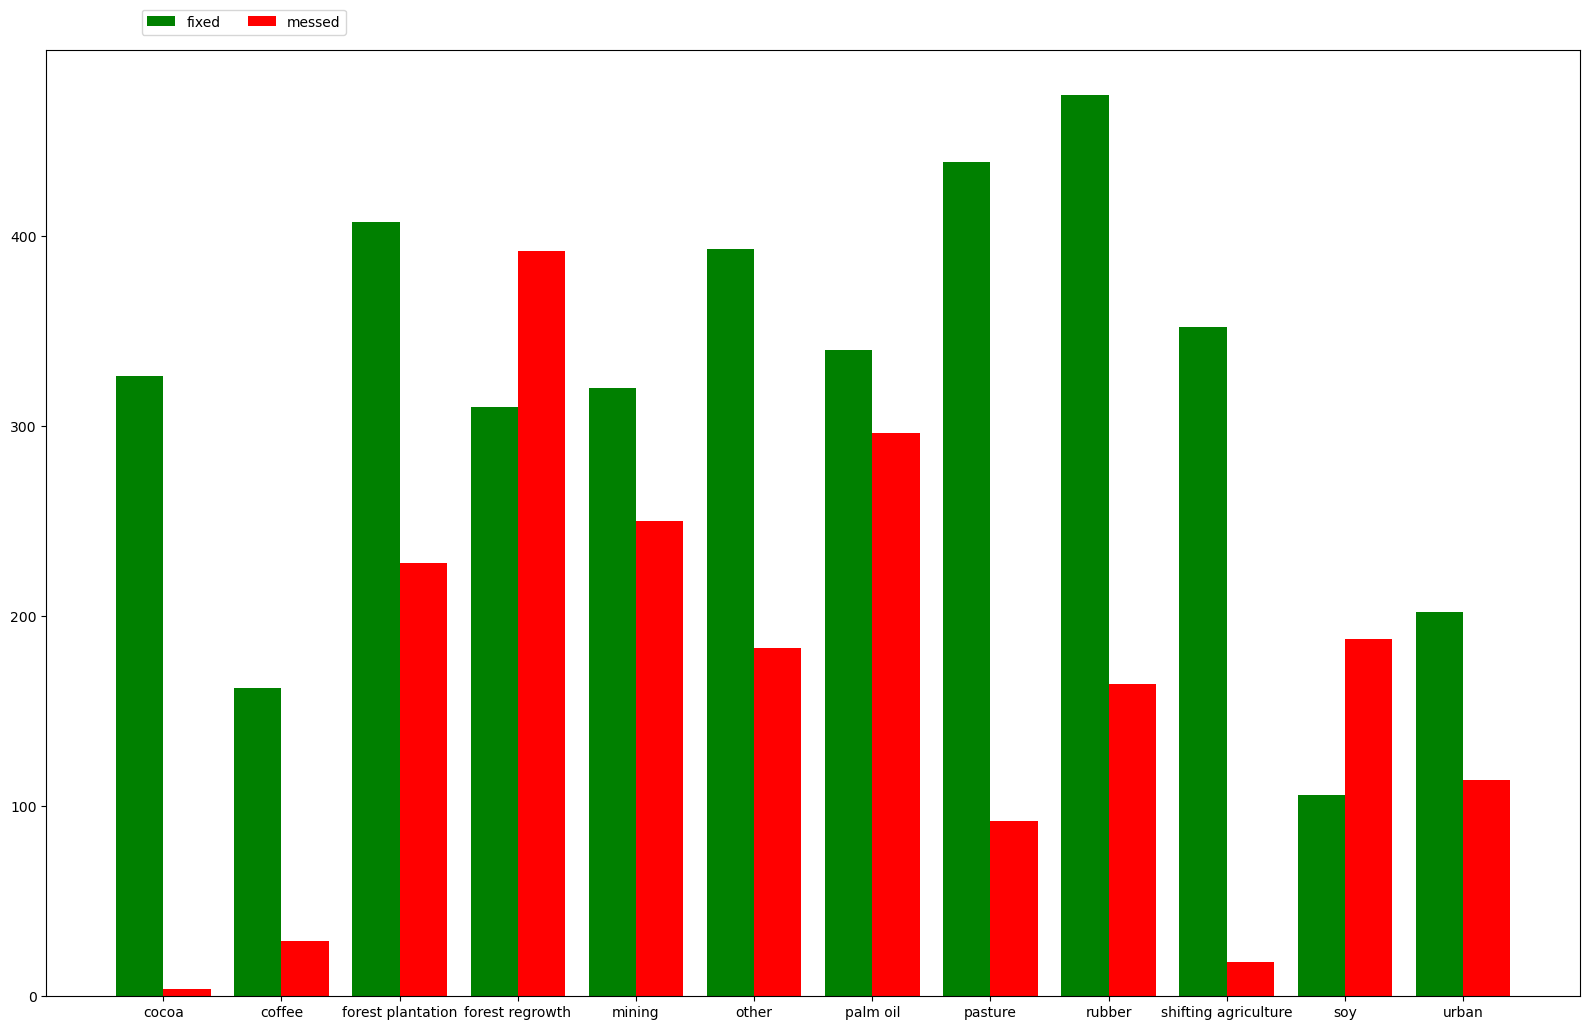

In [180]:

_x = np.arange(len(classes))  # the label locations
fig, ax = plt.subplots(1,figsize=(16,10))

ax.bar(_x-0.2, fixed_counts, width=0.4, color='green', align='center', label='fixed')
ax.bar(_x+0.2, incorrect_counts, width=0.4, color='red', align='center', label='messed')
plt.xticks(_x, classes) 
plt.tight_layout()
plt.legend(bbox_to_anchor=(0.2, 1.05), ncol=5)
plt.show()

In [182]:

cls, base_model_preds = np.unique(df_filtered['no loc  no tab transformer cls'], return_counts=True)
cls, trimodal_preds = np.unique(df_filtered['yes loc  reports_token tab transformer cls'], return_counts=True)

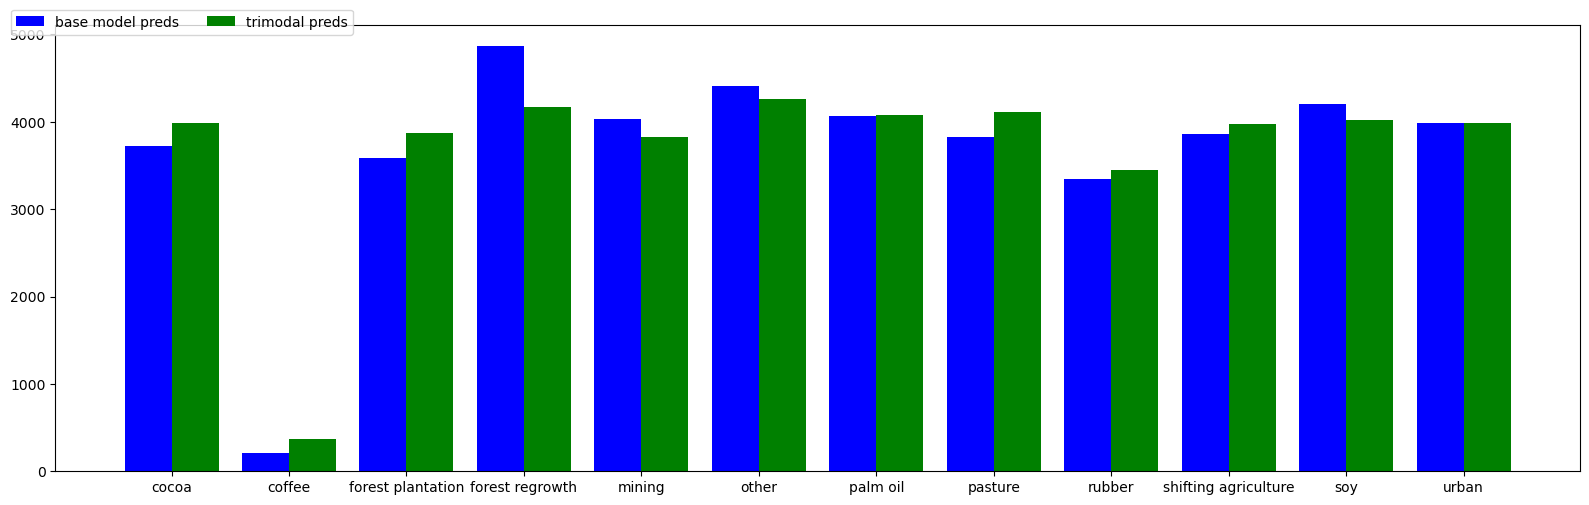

In [187]:

_x = np.arange(len(cls))  # the label locations
fig, ax = plt.subplots(1,figsize=(16,5))

ax.bar(_x-0.2, base_model_preds, width=0.4, color='blue', align='center', label='base model preds')
ax.bar(_x+0.2, trimodal_preds, width=0.4, color='green', align='center', label='trimodal preds')
plt.xticks(_x, classes) 
plt.tight_layout()
plt.legend(bbox_to_anchor=(0.2, 1.05), ncol=5)
plt.show()

In [198]:

    
incorrect_dict = dict(zip(*np.unique(incorrect.country, return_counts=True)))
fixed_dict = dict(zip(*np.unique(fixed.country, return_counts=True)))

In [201]:
for country in labels.country.unique():
    try:
        print(country)
        print('fixed: ',fixed_dict[country] , 'messed: ', incorrect_dict[country])
    except KeyError:
        continue

Ecuador
fixed:  245 messed:  25
Côte d'Ivoire
fixed:  21 messed:  2
Ghana
fixed:  77 messed:  57
Colombia
fixed:  26 messed:  13
Brazil
fixed:  1011 messed:  655
Viet Nam
fixed:  230 messed:  42
Indonesia
fixed:  1133 messed:  890
Malaysia
fixed:  101 messed:  69
Mexico
fixed:  13 messed:  2
Cuba
fixed:  11 messed:  7
Bolivia (Plurinational State of)
fixed:  5 messed:  2
United States of America
Australia
fixed:  3 messed:  3
Guatemala
fixed:  3 messed:  3
Philippines
fixed:  15 messed:  2
Lao People's Democratic Republic
fixed:  45 messed:  23
Peru
fixed:  56 messed:  1
Guyana
fixed:  18 messed:  3
India
fixed:  5 messed:  1
Democratic Republic of the Congo
fixed:  255 messed:  42
Papua New Guinea
fixed:  13 messed:  7
Gabon
fixed:  24 messed:  4
Uganda
fixed:  6 messed:  3
Venezuela (Bolivarian Republic of)
fixed:  14 messed:  3
Sri Lanka
Myanmar
fixed:  33 messed:  32
Suriname
Ethiopia
fixed:  2 messed:  1
Liberia
fixed:  8 messed:  1
Thailand
fixed:  178 messed:  18
Bahamas
Kenya
f

In [23]:

df_filtered

,geometry,driver,sampleid,dataset,split,country,True img yes loc reports_token tabular,True img no loc no tabular,False img yes loc no tabular,False img no loc reports_token tabular,True img no loc reports_token tabular,False img yes loc reports_token tabular,True img yes loc no tabular
1,POINT (-3.252726923505843 6.05540773743447),cocoa,30005848,cocoa.csv,1,Côte d'Ivoire,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
2,POINT (-1.8324904593128795 6.046244921563979),cocoa,30005875,cocoa.csv,1,Ghana,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
6,POINT (-0.7054641038565277 5.624755391523431),cocoa,30007242,cocoa.csv,0,Ghana,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
7,POINT (-79.5647662448441 -1.9379355564808602),cocoa,110003683,cocoa_ecuador.csv,0,Ecuador,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
9,POINT (-0.6413243925703949 6.412757556385085),cocoa,30004120,cocoa.csv,2,Ghana,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
...,...,...,...,...,...,...,...,...,...,...,...,...,...
55298,POINT (76.66305108549047 10.758438413532348),urban,100002981,worldcover.csv,1,India,urban,urban,urban,urban,urban,urban,urban
55299,POINT (106.68137671728651 -6.334442760971974),urban,100009782,worldcover.csv,1,Indonesia,urban,urban,other,other,urban,other,urban
55300,POINT (-35.322382484061244 -5.749666958458276),urban,10427227,mapbiomas.csv,2,Brazil,urban,urban,urban,pasture,urban,pasture,urban
55301,POINT (101.5439344788162 3.154945653990399),urban,100004466,worldcover.csv,1,Malaysia,urban,urban,urban,urban,urban,urban,urban


## Plot and check examples of (i) where the tri-modal helped and (ii) where it made it worse

In [24]:
df_filtered['True img yes loc reports_token tabular'] 

1        cocoa
2        cocoa
6        cocoa
7        cocoa
9        cocoa
         ...  
55298    urban
55299    urban
55300    urban
55301    urban
55302    urban
Name: True img yes loc reports_token tabular, Length: 44109, dtype: object

In [25]:

incorrect = df_filtered.loc[

    (df_filtered['True img yes loc reports_token tabular'] != df_filtered['driver'])
     ]

In [28]:
np.unique(incorrect['driver'], return_counts=True)

(array(['cocoa', 'coffee', 'forest plantation', 'forest regrowth',
        'mining', 'other', 'palm oil', 'pasture', 'rubber',
        'shifting agriculture', 'soy', 'urban'], dtype=object),
 array([ 24, 114, 819, 887, 560, 628, 734, 362, 494,  45, 215, 193]))